# Desiertos de recarga bip! en Santiago

**IIC2433 · Minería de Datos · Entrega final 2026-2**

¿En qué Zonas 777 coinciden muchos inicios de viaje y una baja accesibilidad a recarga bip!, y qué paraderos conviene evaluar para ampliar la cobertura?

El diagnóstico usa los polígonos disponibles de la zonificación denominada **Zona 777**. La matriz de cuatro cuadrantes conserva el criterio de priorización del avance y el ranking por paradero señala emplazamientos concretos. Se agrega una simulación de cobertura para comparar dos maneras de distribuir un mismo número de nuevos puntos.

| Pregunta | Método y salida | Evaluación |
|---|---|---|
| ¿Dónde falta acceso? | Distancia UTM con `cKDTree`, cruce punto-polígono y cuatro cuadrantes | Cobertura a 300 y 500 m y sensibilidad al radio |
| ¿Qué perfiles tienen las zonas? | PCA y K-Means, que entrega etiquetas de perfil | Varianza explicada, cargas, curva del codo y silueta |
| ¿Cuántas subidas laborales registra un paradero? | Ridge y Random Forest **regresor**, que estiman subidas/día | MAE, RMSE y R² sobre comunas retenidas. Baseline de la media |
| ¿Cuántos viajes registrados empiezan por hora? | ARIMA y SARIMA, que pronostican una serie agregada | MAE y RMSE cronológicos. Baseline de la misma hora del día anterior |
| ¿Dónde conviene evaluar nuevos puntos? | Ranking observado y selección por cobertura marginal | Subidas preexistentes al alcance de los sitios simulados, con idéntico presupuesto |

**Respuesta al profesor.** Ridge es regresión lineal regularizada. Junto con Random Forest estima una variable continua usando características de cada paradero, en comunas retenidas. Su utilidad es contrastar la capacidad predictiva y el aporte de las variables de recarga. La ubicación de candidatos se deriva de demanda observada, distancias y cobertura marginal. SARIMA responde a la planificación horaria agregada. PCA y K-Means describen perfiles sin una etiqueta de referencia. Cada comparación usa el mismo objetivo, conjunto de prueba y unidad dentro de su pregunta.

### Reproducción

Instale `requirements.txt`, abra este notebook con el kernel de ese entorno y ejecute todas las celdas desde la carpeta del proyecto. Se leen los originales y se regeneran `resultados/` y `Live_Demo_BIP.html`. La lectura de los siete CSV se hace por bloques y recorre varios GB. El HTML muestra los polígonos y los resultados sin conexión.

### Fuentes y alcance

- ADATRAP, **11–17 de abril de 2026**. Cada fila con fecha válida cuenta como un viaje registrado, sin expansión. Se retienen únicamente fecha y zona de origen. El diagnóstico zonal usa lunes a viernes y el pronóstico usa la semana completa. [Matrices de Viaje DTPM](https://www.dtpm.cl/index.php/documentos/matrices-de-viaje)
- DTPM, `Subidas_Paradero_Estacion_2026.04_v3.xlsx`. Subidas promedio por día laboral del **13–17 de abril**. Se filtra `Modo=BUS` y se suma por código interno. Las subidas incluyen etapas y transbordos. [Subidas por paradero y diccionarios](https://www.dtpm.cl/index.php/documentos/matrices-de-viaje)
- DTPM, **GTFS del 18 de abril de 2026**, incorporado como fuente complementaria. El identificador `stop_id` coincide con el código público de DTPM. El GTFS entra en vigencia un día después del último dato de demanda. Se usa como aproximación a la ubicación y oferta del período. [Archivo oficial GTFS](https://www.dtpm.cl/descargas/gtfs/GTFS_20260418.zip)
- Subsecretaría de Transportes, **catastro fechado el 17 de septiembre de 2024** en los archivos locales. Se deduplican las coordenadas UTM 19S exactas. La vigencia operativa en abril de 2026 queda por verificar. [Catastros bip! del Portal de Datos Abiertos](https://datos.gob.cl/es/group/transporte)
- `Zonas777_V07_04_2014.shp` y sus archivos asociados. El universo usa los códigos que trae la cartografía, incluido el 0, que tiene polígono identificado. La unión conserva todos sus códigos distintos. Se supone WGS84 en el archivo sin `.prj` y se contrasta contra la zona del diccionario de paraderos.


In [1]:
from pathlib import Path
import re, unicodedata, warnings, html, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from scipy.spatial import cKDTree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.neighbors import NearestNeighbors
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pyproj import Transformer

from threadpoolctl import threadpool_limits
from IPython.display import Markdown
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon, Patch
from scipy.spatial.distance import pdist
from sklearn.base import clone
from proyecto_bip import (agregar_viajes, leer_demanda_bus, leer_paraderos_gtfs, leer_poligonos, asignar_poligonos,
                          construir_zonas, simular_cobertura, exportar_mapa)

SEMILLA = 42
RADIO_CERCANO_M, RADIO_AISLAMIENTO_M = 300, 500
TOP_N, SEPARACION_CANDIDATOS_M = 20, 200
RAIZ = Path.cwd().resolve()
ORIG, RESULTADOS = RAIZ / 'datos_originales', RAIZ / 'resultados'
if not ORIG.is_dir():
    raise FileNotFoundError('Ejecute desde la carpeta que contiene datos_originales y el notebook.')
RESULTADOS.mkdir(exist_ok=True)
PROCESADOS = IMAGENES = RESULTADOS
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def guardar_figura(fig, nombre):
    fig.tight_layout()
    fig.savefig(RESULTADOS / nombre, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()

def numero(valor, decimales=0):
    return f'{valor:,.{decimales}f}'.translate(str.maketrans({',':'.', '.':','}))


## 1. Inventario y limpieza

Se consolidan los registros con coordenadas válidas del catastro. `DIC_777.xlsx` es un archivo histórico, con última modificación registrada en 2017. El enlace por código interno deja demasiadas subidas de 2026 sin ubicación. Se usa como control de concordancia cartográfica. Para el análisis principal se enlaza el código público DTPM con el GTFS de abril y se mide la fracción de las subidas que conserva este cruce.

In [2]:
def normalizar_cadena(valor):
    if pd.isna(valor): return ''
    valor = unicodedata.normalize('NFKD', str(valor))
    return ''.join(ch for ch in valor if not unicodedata.combining(ch)).strip().upper()

def float_col(serie):
    texto = serie.astype('string').str.strip().str.replace(' ', '', regex=False)
    texto = texto.str.replace(',', '.', regex=False)
    return pd.to_numeric(texto, errors='coerce').astype('float64')

def archivos_excel(carpeta):
    if not carpeta.is_dir():
        raise FileNotFoundError(f'Falta la carpeta requerida: {carpeta}')
    return sorted(p for p in carpeta.rglob('*.xlsx') if not p.name.startswith('~$'))

def leer_bip(carpeta):
    partes, bitacora = [], []
    libros = archivos_excel(carpeta)
    if not libros:
        raise FileNotFoundError(f'No existen .xlsx en {carpeta}')
    for ruta in libros:
        with pd.ExcelFile(ruta) as libro:
            for hoja in libro.sheet_names:
                muestra = pd.read_excel(libro, sheet_name=hoja, header=None, nrows=30)
                fila_cabecera = None
                for idx, fila in muestra.iterrows():
                    etiquetas = {normalizar_cadena(v) for v in fila.values}
                    if 'ESTE' in etiquetas and 'NORTE' in etiquetas:
                        fila_cabecera = int(idx)
                        break
                if fila_cabecera is None:
                    bitacora.append(f'Omitida {ruta.name} / {hoja}: sin columnas ESTE y NORTE')
                    continue
                tabla = pd.read_excel(libro, sheet_name=hoja, header=fila_cabecera)
                tabla.columns = [normalizar_cadena(c) for c in tabla.columns]
                tabla = tabla.loc[:, ~tabla.columns.duplicated()]
                for columna in ('CODIGO', 'ENTIDAD', 'COMUNA', 'DIRECCION'):
                    if columna not in tabla.columns:
                        tabla[columna] = ''
                tabla['ESTE'] = float_col(tabla['ESTE'])
                tabla['NORTE'] = float_col(tabla['NORTE'])
                tabla['ORIGEN_ARCHIVO'] = ruta.name
                partes.append(tabla[['CODIGO','ENTIDAD','COMUNA','DIRECCION','ESTE','NORTE','ORIGEN_ARCHIVO']])
    if not partes:
        raise ValueError('Ninguna hoja de recarga tiene encabezados válidos ESTE/NORTE.')
    tabla = pd.concat(partes, ignore_index=True)
    n_inicial = len(tabla)
    # Región metropolitana: rangos conservadores solo para evitar coordenadas erróneas.
    tabla = tabla[tabla.ESTE.between(250000, 400000) & tabla.NORTE.between(6200000, 6400000)].copy()
    tabla['COMUNA_NORM'] = tabla.COMUNA.map(normalizar_cadena)
    tabla['ENTIDAD'] = tabla.ENTIDAD.map(normalizar_cadena)
    # Coordenadas únicas identifican un emplazamiento, independientemente de registros repetidos.
    tabla = tabla.drop_duplicates(subset=['ESTE','NORTE']).reset_index(drop=True)
    print(f'BIP: {n_inicial:,} registros brutos → {len(tabla):,} emplazamientos válidos únicos.')
    for advertencia in bitacora[:8]: print('AVISO:', advertencia)
    return tabla

def leer_paraderos(ruta):
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta diccionario geográfico: {ruta}')
    tabla = pd.read_excel(ruta, sheet_name='DIC_777')
    columnas = ['PARADA','SUBIDAS_LABORAL','BAJADAS_LABORAL','COMUNA','REFERENCIA','DISENO_777','X_UTM','Y_UTM']
    # Se valida el esquema del diccionario incluido antes de renombrar.
    nombres = [normalizar_cadena(c) for c in tabla.columns]
    if set(columnas).issubset(nombres):
        tabla.columns = nombres
        tabla = tabla[columnas].copy()
    elif nombres == ['PARADA/EST.METRO','SUBIDAS DIA LABORAL POR PARADA',
                     'BAJADAS DIA LABORAL POR PARADA','COMUNA','REFERENCIA','DISENO_777','X','Y']:
        tabla.columns = columnas
    else:
        raise ValueError(f'DIC_777: esquema inesperado ({list(tabla.columns)}). Revisar diccionario.')
    for c in ['SUBIDAS_LABORAL','BAJADAS_LABORAL','X_UTM','Y_UTM']:
        tabla[c] = float_col(tabla[c])
    tabla['PARADA'] = tabla.PARADA.astype('string').str.strip().str.upper()
    tabla['COMUNA'] = tabla.COMUNA.map(normalizar_cadena)
    tabla['REFERENCIA'] = tabla.REFERENCIA.fillna('').astype(str)
    n_inicial = len(tabla)
    tabla = tabla[tabla.X_UTM.between(250000,400000) & tabla.Y_UTM.between(6200000,6400000)]
    tabla = tabla.dropna(subset=['PARADA'])
    tabla = tabla[tabla.PARADA.str.len().gt(0)]
    tabla = tabla.drop_duplicates(subset=['PARADA','X_UTM','Y_UTM']).reset_index(drop=True)
    print(f'PARADEROS: {n_inicial:,} registros brutos → {len(tabla):,} paradas/ubicaciones válidas.')
    return tabla

ruta_bip = ORIG / 'Lugares de carga'
ruta_dic = ORIG / 'Zona777_ADATRAP' / 'DIC_777.xlsx'
ruta_dtpm = ORIG / 'Subidas_Paradero_Estacion_2026.04_v3.xlsx'
ruta_gtfs = ORIG / 'GTFS_20260418.zip'
ruta_shape = (ruta_dic.parent / 'Zonas777-04-04-2014' / 'Shape' / 'Zonas777_V07_04_2014.shp')
df_bip = leer_bip(ruta_bip)
df_paraderos = leer_paraderos(ruta_dic).rename(columns={'SUBIDAS_LABORAL':'SUBIDAS_DIC'})
geometrias, comunas_shape = leer_poligonos(ruta_shape)
df_bip['zona_777'], solapes_bip = asignar_poligonos(geometrias, df_bip.ESTE, df_bip.NORTE)
df_paraderos['zona_cartografica'], solapes_paradas = asignar_poligonos(
    geometrias, df_paraderos.X_UTM, df_paraderos.Y_UTM)
df_paraderos['zona_777'] = pd.to_numeric(df_paraderos.DISENO_777, errors='coerce').astype('Int64')
validacion = df_paraderos[df_paraderos.zona_777.notna() & df_paraderos.zona_cartografica.notna()]
concordancia = validacion.zona_777.eq(validacion.zona_cartografica).mean()
if not concordancia >= .95:
    raise ValueError(f'Concordancia geográfica inesperada: {concordancia:.1%}')
demanda_bus = leer_demanda_bus(ruta_dtpm)
paradas_gtfs = leer_paraderos_gtfs(ruta_gtfs)
maestro = demanda_bus.merge(paradas_gtfs, on='CODIGO_PUBLICO', how='inner', validate='1:1')
maestro['COMUNA'] = maestro.COMUNA_DTPM.map(normalizar_cadena)
maestro['zona_777'], solapes_gtfs = asignar_poligonos(geometrias, maestro.X_UTM, maestro.Y_UTM)
no_enlazados = demanda_bus.loc[~demanda_bus.PARADA.isin(maestro.PARADA)]
no_enlazados.to_csv(RESULTADOS / 'paraderos_sin_enlace_gtfs.csv', index=False)
fraccion_historica = demanda_bus.loc[demanda_bus.PARADA.isin(df_paraderos.PARADA), 'SUBIDAS_LABORAL'].sum() / demanda_bus.SUBIDAS_LABORAL.sum()
fraccion_subidas = maestro.SUBIDAS_LABORAL.sum() / demanda_bus.SUBIDAS_LABORAL.sum()
print(f'{len(geometrias):,} códigos de zona · Concordancia cartografía/diccionario: {concordancia:.1%} de {len(validacion):,} pares.')
print(f'{len(maestro):,} de {len(demanda_bus):,} códigos BUS enlazados a GTFS.')
print(f'Subidas con ubicación en GTFS: {fraccion_subidas:.2%}. En el diccionario histórico por código interno: {fraccion_historica:.2%}.')
print(f'Puntos sin polígono: {df_bip.zona_777.isna().sum()}. Paraderos sin polígono: {maestro.zona_777.isna().sum()}.')
display(df_bip.groupby('ENTIDAD').size().sort_values(ascending=False).head(8).to_frame('Ubicaciones'))


BIP: 1,928 registros brutos → 1,905 emplazamientos válidos únicos.
PARADEROS: 11,211 registros brutos → 11,111 paradas/ubicaciones válidas.
803 códigos de zona · Concordancia cartografía/diccionario: 98.8% de 11,104 pares.
11,929 de 11,932 códigos BUS enlazados a GTFS.
Subidas con ubicación en GTFS: 99.94%. En el diccionario histórico por código interno: 58.03%.
Puntos sin polígono: 29. Paraderos sin polígono: 176.


,Ubicaciones
ENTIDAD,
FULLCARGA,1607
WALMART,164
METRO,134


## 2. Accesibilidad y cuatro cuadrantes

Cada paradero se compara con **todo** el catastro, incluso con puntos de una zona vecina. La distancia mínima y los radios se calculan en línea recta UTM 19S. Para cada zona se calcula el porcentaje de subidas en paraderos sin recarga a 300 o 500 m y la distancia media ponderada por subidas. El número de puntos **dentro** del polígono se informa como un atributo separado.

Se conserva la regla del avance para paraderos. Demanda alta desde P75 de subidas. Distancia alta desde P75 de distancia. En zonas, demanda alta corresponde al P75 de viajes registrados por día laboral y brecha alta al P75 del porcentaje de subidas sin recarga a 500 m. Los P75 zonales se calculan sobre zonas con viajes y con subidas de bus enlazadas. Las otras quedan como «Sin datos comparables». Los porcentajes de punta usan 07:00–09:00 y 17:00–20:00, con extremo final excluido.

In [3]:
arbol_bip = cKDTree(df_bip[['ESTE','NORTE']].to_numpy())
xy = maestro[['X_UTM','Y_UTM']].to_numpy()
maestro['distancia_min_bip_m'], indices_bip = arbol_bip.query(xy)
for radio in (RADIO_CERCANO_M, RADIO_AISLAMIENTO_M):
    maestro[f'bip_en_{radio}m'] = arbol_bip.query_ball_point(xy, radio, return_length=True)
maestro['bip_mas_cercano'] = df_bip.iloc[indices_bip].ENTIDAD.to_numpy()
trans = Transformer.from_crs(32719, 4326, always_xy=True)
maestro['LON'], maestro['LAT'] = trans.transform(*xy.T)
df_bip['LON'], df_bip['LAT'] = trans.transform(df_bip.ESTE.to_numpy(), df_bip.NORTE.to_numpy())
df_bip.to_csv(RESULTADOS / 'puntos_bip_consolidados.csv', index=False)

COLORES = {'Prioridad crítica':'#ba392d', 'Prioridad de accesibilidad':'#de9e3b',
           'Alta demanda con recarga próxima':'#26737d', 'Menor prioridad':'#aebfc0',
           'Sin datos comparables':'#e8ebea'}

def cuadrantes(alta_demanda, alta_brecha):
    return np.select([alta_demanda & alta_brecha, alta_brecha, alta_demanda],
                     list(COLORES)[:3], default='Menor prioridad')

p75_demanda = maestro.SUBIDAS_LABORAL.quantile(.75)
p75_distancia = maestro.distancia_min_bip_m.quantile(.75)
maestro['prioridad_territorial'] = cuadrantes(maestro.SUBIDAS_LABORAL.ge(p75_demanda),
                                             maestro.distancia_min_bip_m.ge(p75_distancia))
maestro['indice_estres'] = maestro.SUBIDAS_LABORAL * maestro.distancia_min_bip_m / 1000
maestro['dist_centro_km'] = np.hypot(maestro.X_UTM-346900, maestro.Y_UTM-6300100) / 1000
maestro['paraderos_en_500m'] = cKDTree(xy).query_ball_point(xy, 500, return_length=True) - 1
maestro.to_csv(RESULTADOS / 'matriz_paraderos_modelado.csv', index=False)

serie_df, viajes_diarios, auditoria_viajes = agregar_viajes(
    ORIG / 'Viajes_2026-04' / 'Tabla de Viajes', RESULTADOS)
zonas = construir_zonas(geometrias, comunas_shape, viajes_diarios, maestro, df_bip)
con_datos = zonas.viajes.gt(0) & zonas.subidas_bus_dia.gt(0)
umbral_viajes = zonas.loc[con_datos, 'viajes_laborales_dia'].quantile(.75)
umbral_brecha = zonas.loc[con_datos, 'pct_subidas_sin_500m'].quantile(.75)
zonas['cuadrante'] = 'Sin datos comparables'
zonas.loc[con_datos, 'cuadrante'] = cuadrantes(
    zonas.loc[con_datos, 'viajes_laborales_dia'].ge(umbral_viajes),
    zonas.loc[con_datos, 'pct_subidas_sin_500m'].ge(umbral_brecha))
criticas = zonas.cuadrante.eq('Prioridad crítica')
sin_carga = zonas.puntos_bip_internos.eq(0)
fuera_zona = viajes_diarios.loc[~viajes_diarios.zona_777.isin(geometrias), 'viajes'].sum()
print(f'Viajes con fecha válida: {numero(serie_df.viajes_totales.sum())}. Sin código en el mapa: {numero(fuera_zona)}.')
print(f'Zonas comparables: {con_datos.sum()} de {len(zonas)}. P75: {umbral_viajes:.1f} viajes/día y {umbral_brecha:.1f}% de subidas sin cobertura a 500 m.')
display(pd.concat([maestro.prioridad_territorial.value_counts().rename('Paraderos BUS'),
                   zonas.cuadrante.value_counts().rename('Zonas 777')], axis=1).fillna(0).astype(int))


2026-04-11 · 1,320,747 viajes con fecha válida
2026-04-12 · 691,101 viajes con fecha válida
2026-04-13 · 2,617,616 viajes con fecha válida
2026-04-14 · 2,664,062 viajes con fecha válida
2026-04-15 · 2,683,405 viajes con fecha válida
2026-04-16 · 2,668,412 viajes con fecha válida
2026-04-17 · 2,545,727 viajes con fecha válida
Viajes con fecha válida: 15.191.070. Sin código en el mapa: 34.553.
Zonas comparables: 793 de 803. P75: 2406.0 viajes/día y 13.7% de subidas sin cobertura a 500 m.


,Paraderos BUS,Zonas 777
Menor prioridad,6388,422
Alta demanda con recarga próxima,2558,172
Prioridad de accesibilidad,2557,172
Prioridad crítica,426,27
Sin datos comparables,0,10


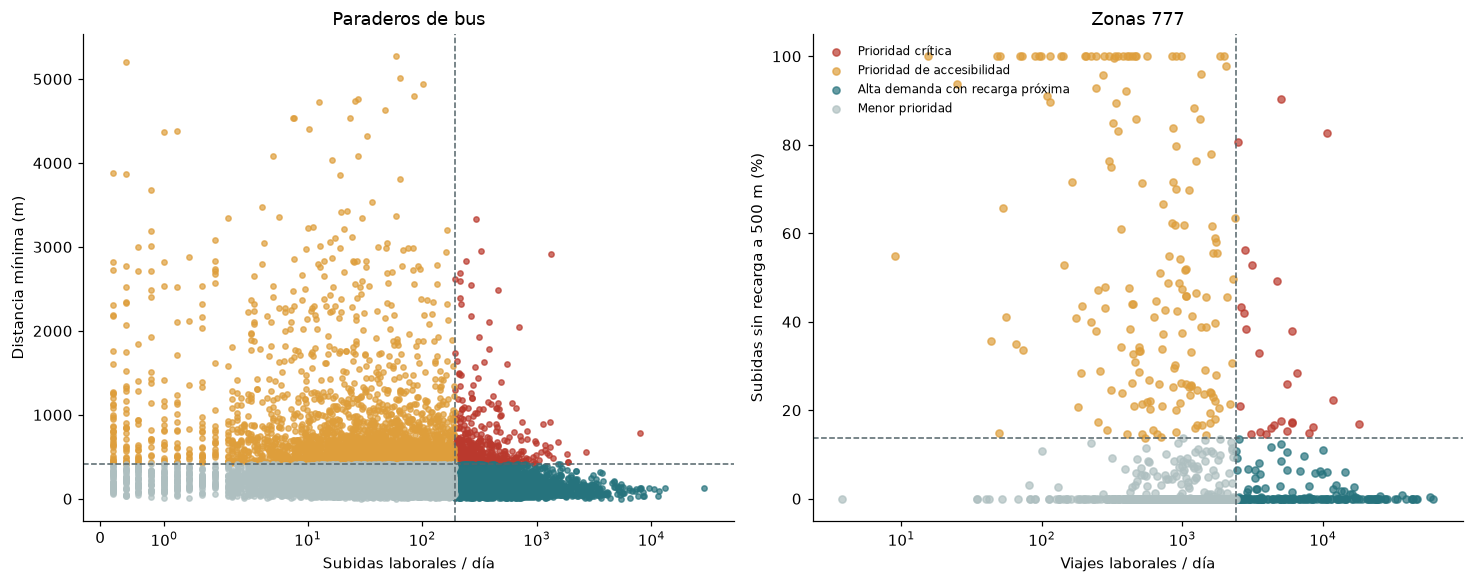

,radio_m,paraderos_sin_recarga,subidas_dia_sin_recarga,pct_subidas
0,300,4926,539812.2,21.5
1,500,2108,194064.4,7.7


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))
for ax, tabla, grupo, x, y, cortes, tit, ejes in [
    (axes[0], maestro, 'prioridad_territorial', 'SUBIDAS_LABORAL', 'distancia_min_bip_m',
     (p75_demanda, p75_distancia), 'Paraderos de bus', ('Subidas laborales / día', 'Distancia mínima (m)')),
    (axes[1], zonas[con_datos], 'cuadrante', 'viajes_laborales_dia', 'pct_subidas_sin_500m',
     (umbral_viajes, umbral_brecha), 'Zonas 777', ('Viajes laborales / día', 'Subidas sin recarga a 500 m (%)')),
]:
    for perfil, color in COLORES.items():
        sub = tabla.loc[tabla[grupo].eq(perfil)]
        if not sub.empty:
            ax.scatter(sub[x], sub[y], s=12 if ax is axes[0] else 22, color=color, alpha=.7, label=perfil)
    ax.set(xscale='symlog', xlabel=ejes[0], ylabel=ejes[1], title=tit)
    ax.axvline(cortes[0], ls='--', c='#53646a', lw=1)
    ax.axhline(cortes[1], ls='--', c='#53646a', lw=1)
axes[1].legend(loc='upper left', fontsize=8, frameon=False)
guardar_figura(fig, '03_matriz_prioridad.png')

resultados_radios = pd.DataFrame([
    {'radio_m': radio, 'paraderos_sin_recarga': int(maestro[f'bip_en_{radio}m'].eq(0).sum()),
     'subidas_dia_sin_recarga': maestro.loc[maestro[f'bip_en_{radio}m'].eq(0), 'SUBIDAS_LABORAL'].sum()}
    for radio in (300, 500)])
resultados_radios['pct_subidas'] = 100 * resultados_radios.subidas_dia_sin_recarga / maestro.SUBIDAS_LABORAL.sum()
resultados_radios.to_csv(RESULTADOS / 'sensibilidad_radios.csv', index=False)
display(resultados_radios.round(1))


## 3. PCA y K-Means en Zona 777

El PCA se ajusta sobre atributos estandarizados. Los volúmenes y conteos de oferta se transforman con `log1p` para limitar el peso de valores extremos. Se usa una variable de cobertura (500 m) en el modelo para evitar darle doble peso junto con 300 m. Las cargas del PCA describen contribuciones a la variación de los datos. El clustering se ajusta en las cinco variables transformadas y se proyecta en dos componentes para la visualización.

Se prueba K-Means para k de 2 a 8 y se elige la mayor silueta. Se usa la curva del codo como diagnóstico complementario. Un grupo se caracteriza como de alta demanda y alta brecha si las medianas de sus zonas cruzan ambos P75. Se reporta también el grupo con mayor mediana de brecha. La matriz de cuadrantes identifica las zonas críticas individuales aunque sus clústeres tengan medianas por debajo de alguno de los cortes. El CSV de viajes carece de un campo de espera con correspondencia inequívoca en el diccionario local, así que la espera no se incluye.

In [5]:
variables_cluster = ['viajes_laborales_dia', 'pct_viajes_punta', 'puntos_bip_internos',
                     'distancia_media_ponderada_m', 'pct_subidas_sin_500m']
base_cluster = zonas.loc[con_datos, variables_cluster].copy()
for col in ['viajes_laborales_dia', 'puntos_bip_internos']:
    base_cluster[col] = np.log1p(base_cluster[col])
estandarizadas = StandardScaler().fit_transform(base_cluster)
pca = PCA(n_components=2)
coordenadas_pca = pca.fit_transform(estandarizadas)
cargas_pca = pd.DataFrame(pca.components_.T, index=variables_cluster, columns=['PC1','PC2'])
cargas_pca.to_csv(RESULTADOS / 'cargas_pca_zona777.csv', index_label='variable')

diagnosticos, etiquetas = [], {}
with threadpool_limits(limits=1):
    for k in range(2, 9):
        km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=30).fit(estandarizadas)
        etiquetas[k] = km.labels_
        diagnosticos.append({'k': k, 'inercia': km.inertia_, 'silueta': silhouette_score(estandarizadas, km.labels_)})
tabla_k = pd.DataFrame(diagnosticos)
tabla_k.to_csv(RESULTADOS / 'evaluacion_kmeans_zona777.csv', index=False)
k_optimo = int(tabla_k.loc[tabla_k.silueta.idxmax(), 'k'])
zonas['cluster'] = pd.Series(pd.NA, index=zonas.index, dtype='Int64')
zonas.loc[con_datos, 'cluster'] = etiquetas[k_optimo]
zonas.loc[con_datos, ['PC1','PC2']] = coordenadas_pca
perfiles = zonas.loc[con_datos].groupby('cluster')[variables_cluster].median()
perfiles['zonas'] = zonas.loc[con_datos].groupby('cluster').size()
perfil_mayor_brecha = int(perfiles.pct_subidas_sin_500m.idxmax())
perfiles['alta_demanda_y_brecha'] = perfiles.viajes_laborales_dia.ge(umbral_viajes) & perfiles.pct_subidas_sin_500m.ge(umbral_brecha)
nombres = {int(i): f'Perfil {i}' for i in perfiles.index}
nombres[perfil_mayor_brecha] += ' · mayor brecha mediana'
zonas['perfil'] = zonas.cluster.map(nombres).fillna('Sin datos comparables')
perfiles['perfil'] = perfiles.index.map(nombres)
perfiles['zonas_criticas'] = zonas.loc[criticas].groupby('cluster').size().reindex(perfiles.index, fill_value=0)
perfiles.to_csv(RESULTADOS / 'perfiles_zona777.csv')
zonas.to_csv(RESULTADOS / 'diagnostico_zona777.csv', index=False)
display(perfiles.round(1), cargas_pca.round(3))
print(f'PCA explica {pca.explained_variance_ratio_.sum():.1%} en dos componentes. Silueta elegida: {tabla_k.silueta.max():.3f}.')


PCA explica 74.7% en dos componentes. Silueta elegida: 0.469.


,viajes_laborales_dia,pct_viajes_punta,puntos_bip_internos,distancia_media_ponderada_m,pct_subidas_sin_500m,zonas,alta_demanda_y_brecha,perfil,zonas_criticas
cluster,,,,,,,,,
0,1364.9,41.3,2.0,197.9,0.0,680,False,Perfil 0,22
1,443.8,42.6,0.0,602.7,71.5,113,False,Perfil 1 · mayor brecha mediana,5


,PC1,PC2
viajes_laborales_dia,-0.379,0.526
pct_viajes_punta,-0.024,0.804
puntos_bip_internos,-0.483,0.004
distancia_media_ponderada_m,0.558,0.196
pct_subidas_sin_500m,0.558,0.198


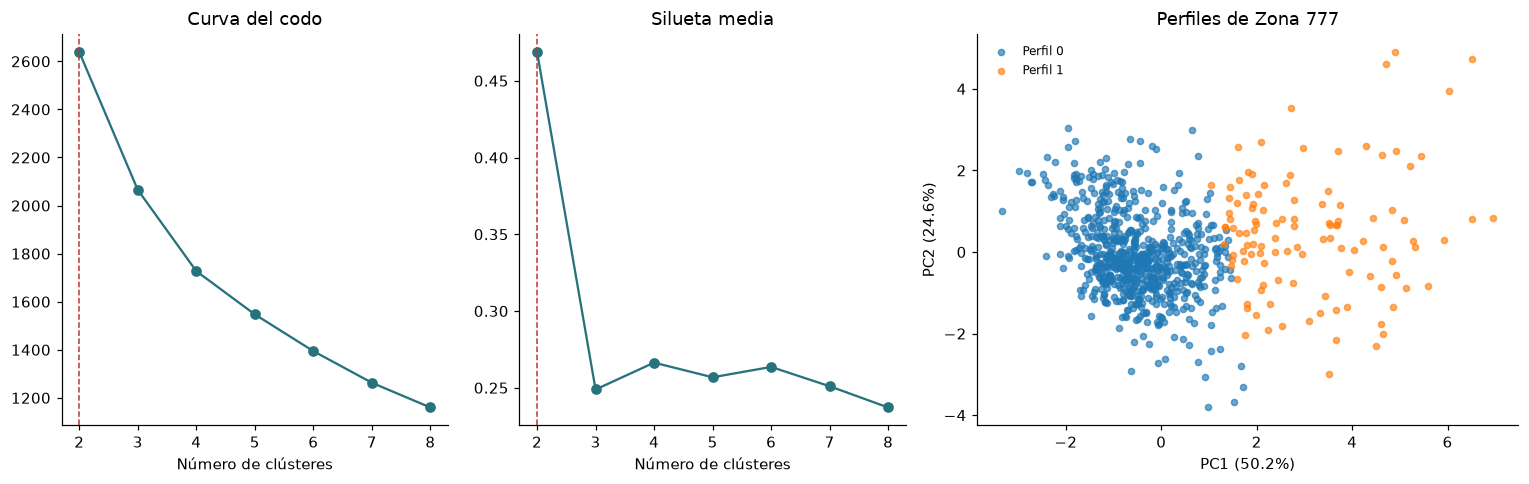

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), gridspec_kw={'width_ratios':[1, 1, 1.4]})
for ax, col, titulo in zip(axes[:2], ['inercia','silueta'], ['Curva del codo','Silueta media']):
    ax.plot(tabla_k.k, tabla_k[col], marker='o', color='#26737d')
    ax.axvline(k_optimo, ls='--', color='#ba392d', lw=1)
    ax.set(xlabel='Número de clústeres', title=titulo)
for id_perfil, sub in zonas.loc[con_datos].groupby('cluster'):
    axes[2].scatter(sub.PC1, sub.PC2, s=16, alpha=.65, label=f'Perfil {id_perfil}')
axes[2].legend(frameon=False, fontsize=8)
axes[2].set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
            ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', title='Perfiles de Zona 777')
guardar_figura(fig, '05_pca_clustering.png')


## 4. Regresión de subidas por paradero

Se comparan media de entrenamiento, Ridge y Random Forest sobre las mismas comunas retenidas, con una semilla fija. Los modelos reciben ubicación, número de rutas de bus programadas en la parada, densidad de paraderos vecinos y variables de acceso a recarga. La comparación adicional de Ridge sin atributos de recarga mide su aporte predictivo incremental con la misma partición. El GTFS es una fotografía próxima a los datos, por lo que el análisis es transversal. Las métricas están en subidas/día y las estimaciones se truncan en cero.

Comunas de prueba: CONCHALI, ESTACION CENTRAL, LA REINA, PROVIDENCIA, PUDAHUEL, QUINTA NORMAL, SAN BERNARDO, SAN RAMON


,Modelo,MAE,RMSE,R2,n_train,n_test
0,Ridge con recarga,175.64,408.21,0.16,9197,2732
1,Ridge sin recarga,179.76,422.91,0.10,9197,2732
2,Random Forest,189.17,470.43,-0.11,9197,2732
3,Dummy (media),222.72,446.53,-0.00,9197,2732


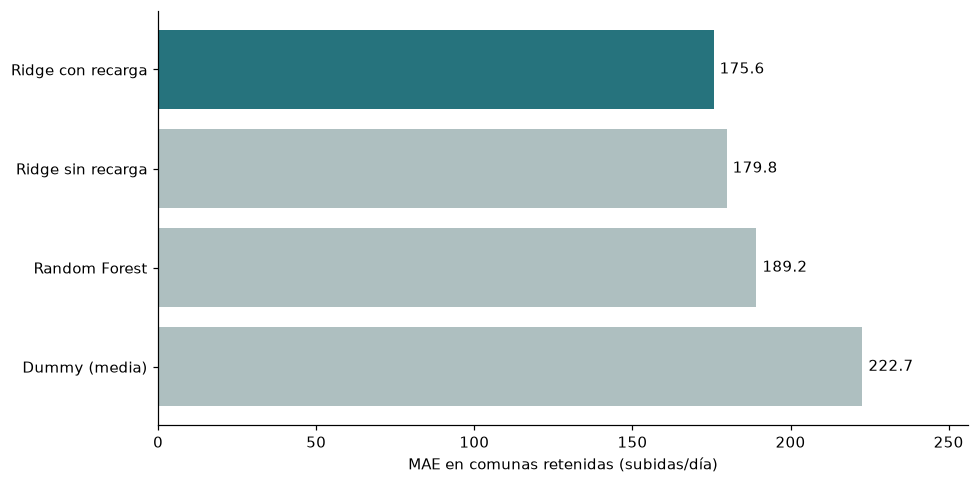

In [7]:
modelo_df = maestro.loc[maestro.COMUNA.ne('')].copy()
base_features = ['rutas_bus_gtfs', 'paraderos_en_500m', 'X_UTM', 'Y_UTM', 'dist_centro_km']
completas = base_features + ['distancia_min_bip_m', 'bip_en_300m', 'bip_en_500m']
y = modelo_df.SUBIDAS_LABORAL
grupos = modelo_df.COMUNA
train, test = next(GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEMILLA).split(modelo_df, y, grupos))
assert set(grupos.iloc[train]).isdisjoint(grupos.iloc[test])
ridge = Pipeline([('escala', StandardScaler()), ('regresion', Ridge(alpha=10))])
modelos = {
    'Dummy (media)': (DummyRegressor(), base_features),
    'Ridge sin recarga': (clone(ridge), base_features),
    'Ridge con recarga': (ridge, completas),
    'Random Forest': (RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=2,
                                             random_state=SEMILLA, n_jobs=4), completas),
}
metricas_espaciales, pred_espaciales = [], {}
for nombre, (modelo, columnas) in modelos.items():
    x = modelo_df[columnas]
    pred = np.maximum(0, modelo.fit(x.iloc[train], y.iloc[train]).predict(x.iloc[test]))
    pred_espaciales[nombre] = pred
    metricas_espaciales.append({'Modelo': nombre, 'MAE': mean_absolute_error(y.iloc[test], pred),
                               'RMSE': np.sqrt(mean_squared_error(y.iloc[test], pred)),
                               'R2': r2_score(y.iloc[test], pred), 'n_train': len(train), 'n_test': len(test)})
metricas_espaciales = pd.DataFrame(metricas_espaciales).sort_values('MAE', ignore_index=True)
metricas_espaciales.to_csv(RESULTADOS / 'metricas_modelos_espaciales.csv', index=False)
print('Comunas de prueba:', ', '.join(sorted(grupos.iloc[test].unique())))
display(metricas_espaciales.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
met = metricas_espaciales.sort_values('MAE', ascending=False)
bars = ax.barh(met.Modelo, met.MAE, color=['#aebfc0']*3+['#26737d'])
ax.bar_label(bars, fmt='%.1f', padding=4)
ax.set(xlabel='MAE en comunas retenidas (subidas/día)', xlim=(0, met.MAE.max()*1.15))
guardar_figura(fig, '04_modelos_espaciales.png')


## 5. Pronóstico horario de viajes registrados

Para cada día de prueba se usan solo las horas anteriores. Se evalúan 24 horas de los días 15, 16 y 17 de abril. El baseline copia la hora correspondiente del día anterior. ARIMA(1,1,1) y SARIMA(1,0,0)(1,0,0,24) pronostican las mismas ventanas. El ciclo estacional es diario y la semana disponible permite una prueba exploratoria de horizonte corto. Se registra la convergencia y se promedian los errores por ventana.

,MAE,RMSE,ventanas,convergencias
Modelo,,,,
Ingenuo estacional (24 h),5847.1,9419.8,3,3
"SARIMA(1,0,0)(1,0,0,24)",7127.2,11571.2,3,3
"ARIMA(1,1,1)",109688.1,139899.8,3,3


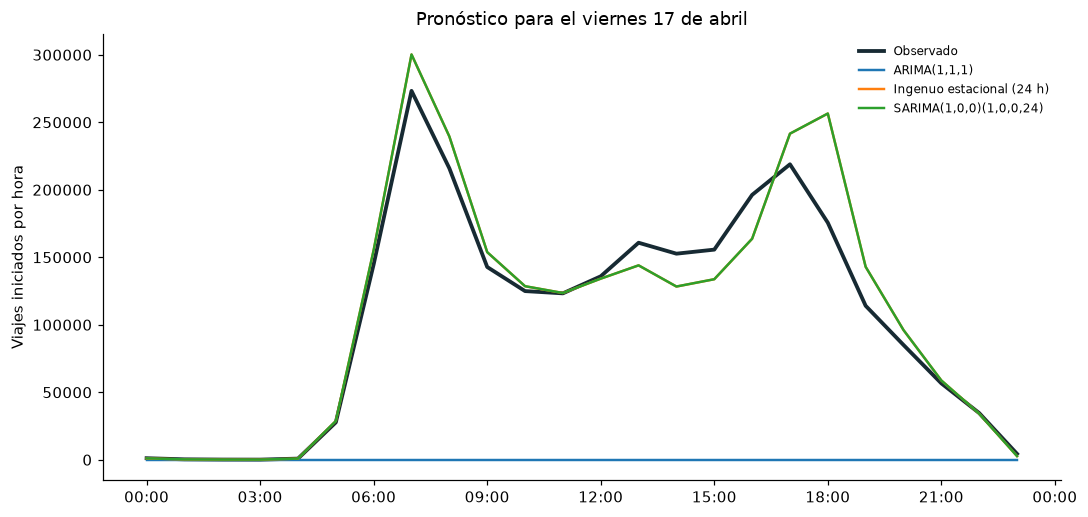

In [8]:
serie = serie_df.set_index('fecha_hora').viajes_totales.asfreq('h').astype(float)
registros, predicciones = [], []
for fecha in pd.date_range('2026-04-15', '2026-04-17', freq='D'):
    train_t = serie[serie.index < fecha]
    test_t = serie[(serie.index >= fecha) & (serie.index < fecha + pd.Timedelta(days=1))]
    assert len(test_t) == 24 and train_t.index.max() < test_t.index.min()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=UserWarning)
        with threadpool_limits(limits=1):
            arima = ARIMA(train_t, order=(1,1,1)).fit(method_kwargs={'maxiter':200})
            sarima = SARIMAX(train_t, order=(1,0,0), seasonal_order=(1,0,0,24),
                             enforce_stationarity=False).fit(disp=False, maxiter=200)
    pronosticos = {'Ingenuo estacional (24 h)': (train_t.tail(24).to_numpy(), True),
                   'ARIMA(1,1,1)': (arima.forecast(24), arima.mle_retvals['converged']),
                   'SARIMA(1,0,0)(1,0,0,24)': (sarima.forecast(24), sarima.mle_retvals['converged'])}
    for nombre, (pred, convergio) in pronosticos.items():
        pred = np.maximum(0, np.asarray(pred))
        registros.append({'Fecha_test': fecha.date().isoformat(), 'Modelo': nombre,
                          'MAE': mean_absolute_error(test_t, pred), 'RMSE': np.sqrt(mean_squared_error(test_t, pred)),
                          'convergio': bool(convergio)})
        predicciones.append(pd.DataFrame({'fecha_hora': test_t.index, 'Modelo': nombre, 'real': test_t.to_numpy(), 'pred': pred}))
metricas_temporales = pd.DataFrame(registros)
pred_temporales = pd.concat(predicciones, ignore_index=True)
metricas_temporales.to_csv(RESULTADOS / 'metricas_modelos_temporales.csv', index=False)
promedios_t = metricas_temporales.groupby('Modelo').agg(MAE=('MAE','mean'), RMSE=('RMSE','mean'),
                                                        ventanas=('Fecha_test','nunique'), convergencias=('convergio','sum')).sort_values('MAE')
display(promedios_t.round(1))
fig, ax = plt.subplots(figsize=(10, 4.8))
ultima = pred_temporales.loc[pred_temporales.fecha_hora.dt.day.eq(17)]
ax.plot(ultima.fecha_hora.unique(), ultima.real.iloc[:24], color='#172a33', lw=2.5, label='Observado')
for nombre, grupo in ultima.groupby('Modelo'):
    ax.plot(grupo.fecha_hora, grupo.pred, lw=1.6, label=nombre)
ax.set(title='Pronóstico para el viernes 17 de abril', ylabel='Viajes iniciados por hora')
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M'))
ax.legend(frameon=False, fontsize=8)
guardar_figura(fig, '06_pronostico_temporal.png')


## 6. Emparejamiento observacional

Como ejercicio vinculado con causalidad, se compara la media de subidas entre paraderos con y sin recarga a 300 m. Se ajusta el puntaje de propensión por posición y distancia al centro y se empareja 1:1 con reemplazo en el soporte común. El balance reporta diferencias de medias estandarizadas (SMD) para las tres covariables. Los resultados describen una asociación ajustada por esas covariables. Comercio, conectividad y frecuencia siguen siendo posibles confundentes y no se mide el efecto de instalar un punto de recarga.

In [9]:
CONF=['X_UTM','Y_UTM','dist_centro_km']
df_obs=maestro.copy()
df_obs['T']=(df_obs.distancia_min_bip_m<=RADIO_CERCANO_M).astype(int)
reporte_psm=None; balance_psm=pd.DataFrame()
if df_obs['T'].nunique()<2:
    print('PSM omitido: solo existe un grupo de accesibilidad.')
else:
    ps=Pipeline([('escala',StandardScaler()),('logistica',LogisticRegression(max_iter=1000,random_state=SEMILLA))])
    ps.fit(df_obs[CONF],df_obs['T'])
    df_obs['propension']=np.clip(ps.predict_proba(df_obs[CONF])[:,1],1e-6,1-1e-6)
    tratados=df_obs[df_obs['T']==1].copy(); controles=df_obs[df_obs['T']==0].copy()
    izq=max(tratados.propension.min(),controles.propension.min())
    der=min(tratados.propension.max(),controles.propension.max())
    tratados=tratados[tratados.propension.between(izq,der)]
    controles=controles[controles.propension.between(izq,der)]
    if min(len(tratados),len(controles))<15:
        print('PSM omitido: menos de 15 observaciones por grupo tras soporte común.')
    else:
        vecinos=NearestNeighbors(n_neighbors=1).fit(controles[['propension']])
        _,idx=vecinos.kneighbors(tratados[['propension']])
        control_match=controles.iloc[idx.ravel()].copy()
        def smd(a,b):
            var=(np.var(a,ddof=1)+np.var(b,ddof=1))/2
            return float((np.mean(a)-np.mean(b))/np.sqrt(var)) if var>0 else np.nan
        for v in CONF:
            balance_psm=pd.concat([balance_psm,pd.DataFrame([{'Covariable':v,
                'SMD_antes':smd(df_obs.loc[df_obs['T']==1,v],df_obs.loc[df_obs['T']==0,v]),
                'SMD_despues':smd(tratados[v],control_match[v])}])],ignore_index=True)
        diferencia=float((tratados.SUBIDAS_LABORAL.to_numpy()-control_match.SUBIDAS_LABORAL.to_numpy()).mean())
        reporte_psm={'n_tratados_soporte':int(len(tratados)),'n_controles_soporte':int(len(controles)),
            'controles_distintos_emparejados':int(control_match.index.nunique()),
            'diferencia_media_ajustada_descriptiva':diferencia,
            'max_smd_post':float(balance_psm.SMD_despues.abs().max())}
        print('Diferencia media ajustada de subidas por día:', round(diferencia, 2))
        display(balance_psm.round(3));print(reporte_psm)
        balance_psm.to_csv(RESULTADOS/'balance_emparejamiento_psm.csv',index=False)

Diferencia media ajustada de subidas por día: 161.52
{'n_tratados_soporte': 6948, 'n_controles_soporte': 4917, 'controles_distintos_emparejados': 2950, 'diferencia_media_ajustada_descriptiva': 161.51951640759933, 'max_smd_post': 0.03892154538086665}


,Covariable,SMD_antes,SMD_despues
0,X_UTM,-0.073,-0.039
1,Y_UTM,0.183,-0.018
2,dist_centro_km,-0.423,0.014


## 7. Ranking y simulación de cobertura

Se filtran los paraderos de prioridad crítica sin recarga a 500 m. El ranking del avance ordena `subidas × distancia en km` hasta 20 sitios, con separación mínima de 200 m. La simulación compara ese orden con una selección voraz del punto que ofrece acceso a más subidas desatendidas entre los sitios candidatos. Cada paradero se contabiliza una sola vez, incluso con radios de nuevos sitios superpuestos. El universo incluye los paraderos BUS enlazados con DTPM y sin recarga a 500 m. Los valores describen subidas preexistentes que quedarían al alcance en el escenario geométrico.

,RANK,CODIGO_PUBLICO,COMUNA,zona_777,SUBIDAS_LABORAL,distancia_min_bip_m,REFERENCIA
0,1,PI1788,MAIPU,162,8021.0,778.4,Parada / Est. Intermodal Del Sol
1,2,PJ2005,PUDAHUEL,522,1338.6,2920.7,Parada / EIM Aeropuerto Red Movilidad
2,3,PD357,LA REINA,256,2680.8,552.9,Parada 5 / (M) Príncipe de Gales
3,4,PC907,LO BARNECHEA,639,695.0,2040.6,Parada / Rotonda Pie Andino
4,5,PC744,VITACURA,192,1316.0,910.5,Avenida Santa María / esq. Carolina Rabat
5,6,PB1005,QUILICURA,557,463.0,2484.0,San Ignacio / esq. Galvarino
6,7,PI356,CERRILLOS,156,1528.2,671.3,Parada / Mall Plaza Oeste
7,8,PC975,LAS CONDES,228,1132.4,886.3,Parada / Portal La Reina
8,9,PC1098,LO BARNECHEA,639,297.0,3336.4,Paseo Los Bravos / esq. Cam. Juan Pablo II
9,10,PC623,LAS CONDES,541,1847.8,535.3,General Blanche / esq. Sn. C. de Apoquindo


,metodo,sitios,paradero,subidas_adicionales_con_cobertura,subidas_acumuladas_con_cobertura,paraderos_cubiertos
4,Índice del avance,5,L-15-12-50-PO,1871.8,18557.4,32
9,Índice del avance,10,L-17-13-10-OP,1989.2,26069.2,53
19,Índice del avance,20,L-16-10-35-NS,908.6,35876.8,97
24,Cobertura marginal,5,L-10-31-25-OP,2600.6,22690.4,58
29,Cobertura marginal,10,L-17-24-50-SN,2286.2,34739.0,131
39,Cobertura marginal,20,T-17-136-OP-5,1704.8,54091.0,235


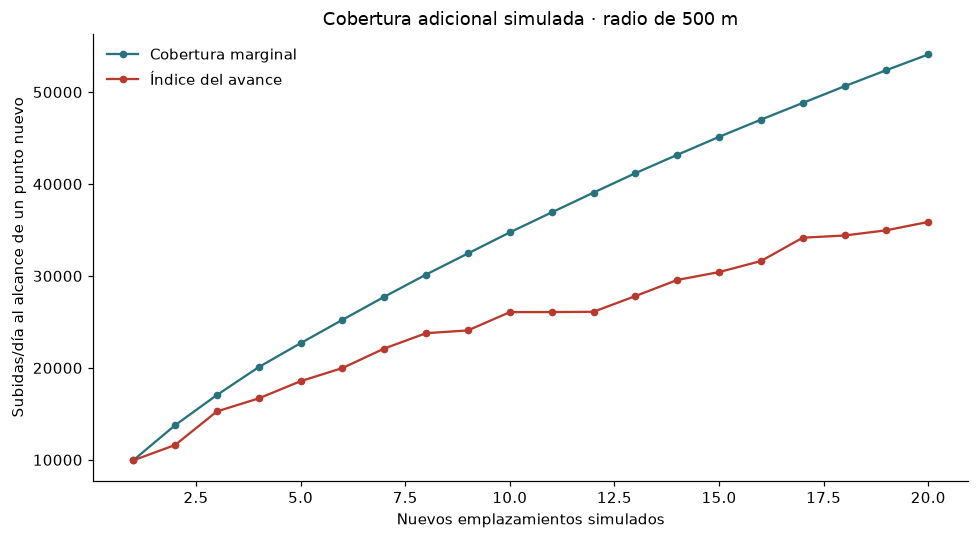

In [10]:
candidatos = maestro.loc[maestro.prioridad_territorial.eq('Prioridad crítica') &
                         maestro.bip_en_500m.eq(0)].sort_values(
                             ['indice_estres','SUBIDAS_LABORAL','PARADA'], ascending=[False,False,True])
indices, ubicaciones = [], []
for fila in candidatos.itertuples():
    punto = np.array([fila.X_UTM, fila.Y_UTM])
    if all(np.linalg.norm(punto-previo) >= SEPARACION_CANDIDATOS_M for previo in ubicaciones):
        indices.append(fila.Index)
        ubicaciones.append(punto)
    if len(indices) == TOP_N:
        break
ranking = candidatos.loc[indices].reset_index(drop=True)
ranking.insert(0, 'RANK', np.arange(1, len(ranking)+1))
ranking.to_csv(RESULTADOS / 'ranking_candidatos_bip.csv', index=False)
cobertura = simular_cobertura(maestro, candidatos, ranking, 500, TOP_N, SEPARACION_CANDIDATOS_M)
cobertura.to_csv(RESULTADOS / 'comparacion_cobertura_500m.csv', index=False)
display(ranking[['RANK','CODIGO_PUBLICO','COMUNA','zona_777','SUBIDAS_LABORAL','distancia_min_bip_m','REFERENCIA']].head(10).round(1))
display(cobertura.loc[cobertura.sitios.isin([5,10,20])].round(1))
fig, ax = plt.subplots(figsize=(9, 5))
for (nombre, tabla), color in zip(cobertura.groupby('metodo'), ['#26737d','#ba392d']):
    ax.plot(tabla.sitios, tabla.subidas_acumuladas_con_cobertura, marker='o', ms=4, color=color, label=nombre)
ax.legend(frameon=False)
ax.set(xlabel='Nuevos emplazamientos simulados', ylabel='Subidas/día al alcance de un punto nuevo',
       title='Cobertura adicional simulada · radio de 500 m')
guardar_figura(fig, '08_ranking_candidatos.png')


## 8. Mapa para el live demo y auditoría

Abra `Live_Demo_BIP.html`. El mapa permite explorar los cuadrantes, alternar la oferta y los candidatos, ampliar una zona y comparar ambas estrategias. Los polígonos corresponden a la cartografía local de DTPM. El mapa usa norte arriba y distancias UTM. La vista inicial resalta las zonas críticas y los candidatos por índice.

Verificación completada. Mapa: Live_Demo_BIP.html


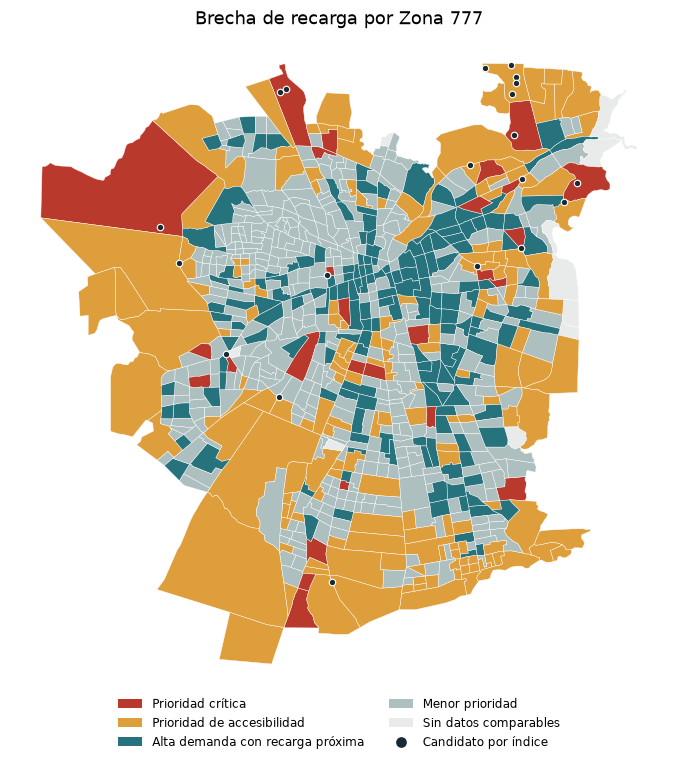

In [11]:
import shapely

fig, ax = plt.subplots(figsize=(8, 7))
parches, tonos = [], []
for z in zonas.itertuples(index=False):
    for poligono in shapely.get_parts(geometrias[z.zona_777]):
        parches.append(Polygon(poligono.exterior.coords))
        tonos.append(COLORES[z.cuadrante])
ax.add_collection(PatchCollection(parches, facecolors=tonos, edgecolors='white', linewidths=.28))
ax.scatter(ranking.X_UTM, ranking.Y_UTM, s=18, facecolor='#172a33', edgecolor='white', linewidth=.75, zorder=3)
ax.autoscale()
ax.set(aspect='equal', title='Brecha de recarga por Zona 777')
ax.axis('off')
leyenda = [Patch(facecolor=color, label=nombre) for nombre,color in COLORES.items()]
leyenda.append(plt.Line2D([], [], color='#172a33', marker='o', linestyle='none', label='Candidato por índice'))
ax.legend(handles=leyenda, loc='lower center', bbox_to_anchor=(.5,-.10), ncol=2, frameon=False, fontsize=8)
guardar_figura(fig, '09_mapa_zona777.png')

ruta_mapa = RAIZ / 'Live_Demo_BIP.html'
exportar_mapa(ruta_mapa, RAIZ / 'mapa_bip_plantilla.html', geometrias, zonas, df_bip, candidatos, cobertura)

assert len(zonas) == len(geometrias) and zonas.zona_777.is_unique
assert zonas.puntos_bip_internos.sum() == df_bip.zona_777.notna().sum()
assert zonas.loc[con_datos, 'cluster'].notna().all()
assert zonas.loc[con_datos, 'pct_subidas_sin_300m'].ge(zonas.loc[con_datos, 'pct_subidas_sin_500m']).all()
assert maestro.PARADA.is_unique and maestro.SUBIDAS_LABORAL.ge(0).all()
assert maestro.bip_en_500m.eq(0).eq(maestro.distancia_min_bip_m.gt(500)).all()
assert maestro.bip_en_300m.eq(0).eq(maestro.distancia_min_bip_m.gt(300)).all()
assert ranking.PARADA.is_unique and ranking.bip_en_500m.eq(0).all()
assert (pdist(ranking[['X_UTM','Y_UTM']]) >= SEPARACION_CANDIDATOS_M).all()
assert cobertura.groupby('metodo').sitios.max().eq(len(ranking)).all()
assert cobertura.groupby('metodo').subidas_acumuladas_con_cobertura.diff().dropna().ge(0).all()
assert len(serie_df) == 168 and auditoria_viajes.viajes_validos.sum() == viajes_diarios.viajes.sum()
assert metricas_temporales.groupby('Modelo').Fecha_test.nunique().eq(3).all()
assert (serie_df.viajes_totales.sum() > 0) and ruta_mapa.stat().st_size > 10000

final_cobertura = cobertura.groupby('metodo').tail(1).set_index('metodo')
resumen = {
    'viajes_validos_semana': int(serie_df.viajes_totales.sum()), 'viajes_sin_poligono': int(fuera_zona),
    'zonas_en_cartografia': len(zonas), 'zonas_comparables': int(con_datos.sum()),
    'zonas_criticas': int(criticas.sum()), 'zonas_criticas_sin_puntos_internos': int((criticas & sin_carga).sum()),
    'p75_viajes_zona': float(umbral_viajes), 'p75_pct_brecha_zona': float(umbral_brecha),
    'puntos_bip': len(df_bip), 'puntos_sin_poligono': int(df_bip.zona_777.isna().sum()),
    'asignaciones_bip_con_solape': solapes_bip, 'asignaciones_paradas_con_solape': solapes_paradas,
    'asignaciones_gtfs_con_solape': solapes_gtfs, 'paraderos_gtfs_sin_poligono': int(maestro.zona_777.isna().sum()),
    'concordancia_zona_diccionario_cartografia': float(concordancia),
    'paraderos_bus_enlazados': len(maestro), 'paraderos_bus_dtpm': len(demanda_bus),
    'pct_subidas_dtpm_con_ubicacion': float(100*fraccion_subidas),
    'pct_subidas_por_codigo_interno_diccionario': float(100*fraccion_historica),
    'paraderos_criticos': int(maestro.prioridad_territorial.eq('Prioridad crítica').sum()),
    'paraderos_aislados_500m': int(maestro.bip_en_500m.eq(0).sum()),
    'k': k_optimo, 'silueta': float(tabla_k.silueta.max()),
    'pca_varianza_2d': float(pca.explained_variance_ratio_.sum()), 'perfil_mayor_brecha': perfil_mayor_brecha,
    'perfiles_alta_demanda_y_brecha': perfiles.index[perfiles.alta_demanda_y_brecha].to_list(),
    'n_candidatos': len(ranking), 'n_elegibles': len(candidatos),
    'cobertura_500m_final': final_cobertura.subidas_acumuladas_con_cobertura.to_dict(),
    'metricas_espaciales': metricas_espaciales.to_dict(orient='records'),
    'metricas_temporales': promedios_t.reset_index().to_dict(orient='records'),
    'psm_descriptivo': reporte_psm,
    'fuentes': [p.relative_to(RAIZ).as_posix() for p in [ruta_bip, ruta_dic, ruta_dtpm, ruta_shape, ruta_gtfs]],
    'mapa': ruta_mapa.name,
}
(RESULTADOS / 'resumen_auditoria.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding='utf-8')
print('Verificación completada. Mapa:', ruta_mapa.name)


## 9. Resultados y límites

El resumen se calcula sobre las salidas de esta ejecución. Los radios representan distancias en línea recta. La accesibilidad a pie debe verificarse con calles, cruces, barreras y horarios. Vivienda, densidad comercial y modos alternativos de pago pueden cambiar la interpretación de la brecha. El catastro es anterior a la demanda y no mide recargas, capacidad ni disponibilidad efectiva. Los viajes registrados y las subidas son unidades diferentes y pueden incluir más de un registro por persona. La simulación mantiene fija la demanda y supone disponibilidad de los sitios seleccionados.

In [12]:
esp = metricas_espaciales.iloc[0]
temp_nombre, temp = next(iter(promedios_t.iterrows()))
ridge_mae = metricas_espaciales.set_index('Modelo').MAE
top = ranking.iloc[0]
perfil_brecha = perfiles.loc[perfil_mayor_brecha]
texto_perfiles = (f'{perfiles.alta_demanda_y_brecha.sum()} perfiles cruzan ambos P75 en sus medianas.'
                  if perfiles.alta_demanda_y_brecha.any() else 'Ningún perfil cruza ambos P75 en sus medianas.')
display(Markdown(f"""
- **Diagnóstico.** {int(criticas.sum())} de {int(con_datos.sum())} zonas comparables tienen alta demanda y alta brecha. En {int((criticas & sin_carga).sum())} de ellas el catastro no ubica puntos dentro del polígono. El cruce por distancia también captura el acceso desde zonas vecinas.
- **Perfiles.** K-Means eligió **k={k_optimo}** (silueta {numero(tabla_k.silueta.max(), 2)}). El perfil {perfil_mayor_brecha} agrupa {int(perfil_brecha.zonas)} zonas y tiene una brecha mediana de {numero(perfil_brecha.pct_subidas_sin_500m, 1)}%. {texto_perfiles} PCA conserva {numero(100*pca.explained_variance_ratio_.sum(), 1)}% de la varianza.
- **Regresión.** {esp.Modelo} logra el menor MAE en esta partición ({numero(esp.MAE, 1)} subidas/día). Ridge con recarga registra {numero(ridge_mae['Ridge con recarga'], 1)}, frente a {numero(ridge_mae['Ridge sin recarga'], 1)} de Ridge sin recarga. La diferencia caracteriza este conjunto de prueba.
- **Pronóstico.** {temp_nombre} obtiene el menor MAE medio ({numero(temp.MAE)} viajes/hora) en tres ventanas. El MAE del baseline estacional es {numero(promedios_t.loc['Ingenuo estacional (24 h)', 'MAE'])} viajes/hora.
- **Ubicación.** El primer sitio por índice es **{top.CODIGO_PUBLICO}**, {top.COMUNA.title()}, con {numero(top.SUBIDAS_LABORAL)} subidas/día y {numero(top.distancia_min_bip_m)} m al bip! más cercano. Con {len(ranking)} sitios bajo el escenario de 500 m, la cobertura marginal alcanza {numero(final_cobertura.loc['Cobertura marginal', 'subidas_acumuladas_con_cobertura'])} subidas/día ya registradas. El ranking por índice alcanza {numero(final_cobertura.loc['Índice del avance', 'subidas_acumuladas_con_cobertura'])}.
"""))



- **Diagnóstico.** 27 de 793 zonas comparables tienen alta demanda y alta brecha. En 6 de ellas el catastro no ubica puntos dentro del polígono. El cruce por distancia también captura el acceso desde zonas vecinas.
- **Perfiles.** K-Means eligió **k=2** (silueta 0,47). El perfil 1 agrupa 113 zonas y tiene una brecha mediana de 71,5%. Ningún perfil cruza ambos P75 en sus medianas. PCA conserva 74,7% de la varianza.
- **Regresión.** Ridge con recarga logra el menor MAE en esta partición (175,6 subidas/día). Ridge con recarga registra 175,6, frente a 179,8 de Ridge sin recarga. La diferencia caracteriza este conjunto de prueba.
- **Pronóstico.** Ingenuo estacional (24 h) obtiene el menor MAE medio (5.847 viajes/hora) en tres ventanas. El MAE del baseline estacional es 5.847 viajes/hora.
- **Ubicación.** El primer sitio por índice es **PI1788**, Maipu, con 8.021 subidas/día y 778 m al bip! más cercano. Con 20 sitios bajo el escenario de 500 m, la cobertura marginal alcanza 54.091 subidas/día ya registradas. El ranking por índice alcanza 35.877.
